# CMI Problematic Internet Use — Pure Handcrafted Autocorrelation Baseline & Multi-Library `SequenceExtractor`

This notebook implements a **100% handcrafted, zero-ML baseline** (no LightGBM, no Ridge, no trees, no supervised regression fitting) for the **Child Mind Institute — Problematic Internet Use** competition (metric: **Quadratic Weighted Kappa** on ordinal `sii` in `{0, 1, 2, 3}`), built in the style of `multi-branch_version_3.ipynb`:

1. **Handcrafted Autocorrelation & Circadian Baseline (`Src/baseline_utils.py`)**: Deterministic scoring over DSP-verified autocorrelation & circadian physiology—grounded in `dsp-slides.pdf` (zero-mean autocovariance, unbiased overlap scaling, zero-phase Butterworth `sosfiltfilt` anti-aliasing below `0.1 Hz` Nyquist, Hann Welch PSD), `cr7_kimmitch` (`PpgHr.swift`, `CircadianEngine.swift`, `SedentaryDetector.swift`, `WakeMotionRefinement.swift`, `SleepAccel.swift`, `SleepDebt.swift`), `OpenStrap/analytics` (van Hees 5-deg/5-min SIB sleep window, Phillips 2017 SRI, Fisher circular social jetlag, calibration-invariant `dynAmp`/MAD, spherical rotation & nocturnal upright posture, Bauer PRSA `AC/DC`, Page CUSUM), and `mad-lab-fau/sleep_analysis` (Cole-Kripke 1992, pediatric/adolescent Sadeh 1994, Webster 1982 morphological rescoring).
2. **Modular Open-Source `SequenceExtractor` & `TSAugmentor` (`Src/base_utils.py`)**: Uses **`tsaug`** (`AddNoise`, `Drift`, `TimeWarp`, `Crop`, `Dropout`), **`tsfel`** (`statistical|temporal|spectral` domain extractors), **`tsfresh`** (`MinimalFCParameters` & custom circadian FFT/autocorrelation features), **`pycatch22`** / **`sktime.Catch22`** (`catch24` canonical nonlinear descriptors), **`tsflex`** (`FeatureCollection` multi-scale `"2h"`, `"6h"`, `"12h"` strided rolling windows), **`seglearn`** (`Segment` + `FeatureRep` + `PadTrunc` kinematic/EMG features), **`statsmodels`** (`pacf` + `seasonal_decompose`), **`scipy.signal`** (`stft`, `welch`, `lombscargle`), **`PyWavelets` (`pywt`)** (`cwt` + `wavedec` DWT), **`pyts`** (`RecurrencePlot`), and leak-free **missing data & imputation experimentation** (`non_wear_policy`, `interp_mode`, `impute_long_gaps`, `min_valid_wear_days`, `missing_feature_strategy`: `keep_nan`, `group_age_median`, `median`, `knn`, `iterative`) tuned via **Grid** and **Bayesian** search (**no Evo**) and scored end-to-end against `submission.csv`.


In [1]:
import os
import sys
import json
import warnings
import importlib
from pathlib import Path

# Ensure conda Library\bin is on PATH on Windows so SciPy/NumPy/Matplotlib load cleanly
_py_env = Path(sys.executable).parent
_lib_bin = _py_env / "Library" / "bin"
if _lib_bin.is_dir() and str(_lib_bin) not in os.environ.get("PATH", ""):
    os.environ["PATH"] = str(_lib_bin) + os.pathsep + str(_py_env) + os.pathsep + os.environ.get("PATH", "")

import numpy as np
import pandas as pd
import matplotlib
if not os.environ.get("MPLBACKEND"):
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

import tsaug
import tsfel
import tsfresh
import pycatch22
import tsflex
from seglearn.transform import Segment as SeglearnSegment, FeatureRep as SeglearnFeatureRep, PadTrunc as SeglearnPadTrunc
from sktime.transformations.panel.catch22 import Catch22 as SktimeCatch22

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedShuffleSplit

warnings.filterwarnings("ignore")

current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == "notebooks":
    workspace_root = os.path.dirname(current_dir)

for _folder in ("Src", "src"):
    _candidate = os.path.join(workspace_root, _folder)
    if os.path.isdir(_candidate) and _candidate not in sys.path:
        sys.path.insert(0, _candidate)

import baseline_utils
import base_utils

importlib.reload(baseline_utils)
importlib.reload(base_utils)

from baseline_utils import (
    DEFAULT_HANDCRAFTED_PARAMS,
    HandcraftedAutocorrelationBaseline,
    batch_extract_handcrafted_autocorr_features,
    quadratic_weighted_kappa,
)
from base_utils import (
    DEFAULT_SEQUENCE_EXTRACTOR_PARAMS,
    HandcraftedSequenceBaselineEstimator,
    HierarchicalBayesSearchCV,
    NoopActigraphyOptions,
    SequenceExtractor,
    SKOPT_AVAILABLE,
    TSAugmentor,
    build_quick_results_df,
    candidate_accuracy_pct,
    candidate_score,
    deduplicate_param_grid,
    evaluate_holdout,
    export_submission,
    extract_successful_fold_scores,
    find_data_root,
    library_status,
    load_cmi_dataset,
    prepare_bayesian_space,
    refit_valid_candidate,
    run_validation_searches,
    strip_leaky_columns,
)

if SKOPT_AVAILABLE:
    from skopt.space import Categorical, Integer, Real

_lib_stat = library_status()
print("Imports loaded successfully (Pure Handcrafted Baseline, zero ML models)")
print("Installed & active open-source libs:", [k for k, v in _lib_stat.items() if v])
print("Unavailable optional libs:", [k for k, v in _lib_stat.items() if not v])
print("Workspace root:", workspace_root)


Imports loaded successfully (Pure Handcrafted Baseline, zero ML models)
Installed & active open-source libs: ['scipy', 'pywt', 'seglearn', 'tsaug', 'tsfel', 'tsfresh', 'pycatch22', 'tsflex', 'sktime', 'catch22_sktime', 'statsmodels', 'pyts', 'skopt', 'tsai']
Unavailable optional libs: ['functime']
Workspace root: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use


# Setup


In [2]:
experiment_name = "cmi_piu_handcrafted_baseline"
TARGET_COL = "sii"

# Set True for fast sampled test (37 datapoints); False runs on all labeled subjects & parquets
use_sample_data = True
sample_max_subjects = 37
save_results = not use_sample_data  # Skip writing files on sample/debug runs
keep_history = False                # Overwrite latest CSV/JSON instead of timestamped copies

search_mode = "bayes"  # Choose "bayes" or "grid" (no evo)
random_state = 42
n_splits = 5           # 1 -> StratifiedShuffleSplit; >=2 -> StratifiedKFold
train_size = 0.8
n_iter = 8             # Bayesian trials across tsaug, tsfel, tsfresh, tsflex, pycatch22, seglearn & missingness
verbose = 1
error_score = -1.0
n_jobs = 1

search_mode = str(search_mode).strip().lower()
if search_mode not in ("bayes", "grid"):
    raise ValueError("search_mode must be 'bayes' or 'grid'")

results_dir = (
    Path(workspace_root) / f"results_{experiment_name}_{TARGET_COL}_{search_mode}"
    if save_results
    else None
)

if n_splits <= 1:
    cv_object = StratifiedShuffleSplit(
        n_splits=1,
        test_size=(1.0 - train_size),
        random_state=random_state,
    )
else:
    cv_object = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

VALIDATION_PARAM_SPACE = {
    "validation_mode": ["stratified_subject"],
}
print(f"Configured {experiment_name} | mode={search_mode} | n_splits={n_splits} | sample={use_sample_data} ({sample_max_subjects}) | save_results={save_results}")


Configured cmi_piu_handcrafted_baseline | mode=bayes | n_splits=5 | sample=True (37)


# Misc


In [3]:
extractor = SequenceExtractor(
    noop=NoopActigraphyOptions(),
    **DEFAULT_SEQUENCE_EXTRACTOR_PARAMS,
)

augmentor = TSAugmentor(prob=0.0, per_aug_prob=0.5, random_state=random_state)

clf = HandcraftedSequenceBaselineEstimator(
    extractor=extractor,
    augmentor=augmentor,
    scoring_rule="autocorr_spectral_rule",
    primary_target=TARGET_COL,
    threshold_calibration="optimize_qwk",
    verbose=verbose,
    random_state=random_state,
)

pipeline = Pipeline([("estimator", clf)])
print("Pure Handcrafted Pipeline constructed with", len(pipeline.get_params(deep=True)), "deep parameters.")


Pure Handcrafted Pipeline constructed with 124 deep parameters.


# Prep


In [4]:
data_root = find_data_root()
train_df = load_cmi_dataset(
    data_root=data_root,
    split="train",
    dropna_target=True,
    max_subjects=(sample_max_subjects if use_sample_data else None),
    random_state=random_state,
)

experiment_df = train_df
del train_df

print(f"Data root: {data_root}")
print(f"Labeled training subjects: {len(experiment_df)} | Actigraphy parquet available: {int(experiment_df['has_actigraphy'].sum())}")
print("Target sii distribution:", experiment_df[TARGET_COL].value_counts().sort_index().to_dict())

# Inspect exact raw tabular & parquet inputs (after stripping leaky PCIAT/sii target columns)
_raw_tab_cols = [c for c in strip_leaky_columns(experiment_df).columns if c not in {"id", "series_path", "has_actigraphy"}]
_first_pq_path = experiment_df.loc[experiment_df["has_actigraphy"] == True, "series_path"].dropna().iloc[0]
_raw_pq_cols = list(pd.read_parquet(_first_pq_path).columns)
print(f"Raw tabular input columns (non-leaky): {len(_raw_tab_cols)} | Raw parquet actigraphy columns: {len(_raw_pq_cols)} {_raw_pq_cols}")
print(f"feature_families active ({len(extractor.feature_families.split('|'))}): {extractor.feature_families}")

# Preview ALL open-source extractors: tsfel, tsfresh, tsflex, pycatch22, seglearn, statsmodels, pywt, pyts & tsaug
_preview_df = experiment_df.head(8)
_preview_feats = extractor.fit_transform(strip_leaky_columns(_preview_df), _preview_df[TARGET_COL])
_preview_chunks = extractor.transform_chunks(_preview_df)

_aug_preview = TSAugmentor(prob=1.0, per_aug_prob=0.75, jitter_sigma=0.02, warp_sigma=0.05, time_warp_max_speed_ratio=1.25, random_state=random_state)
_aug_chunks = _aug_preview.augment_array(_preview_chunks["chunks"]) if len(_preview_chunks["chunks"]) else _preview_chunks["chunks"]
_aug_delta = float(np.mean(np.abs(_aug_chunks - _preview_chunks["chunks"]))) if len(_aug_chunks) else 0.0

print(
    f"SequenceExtractor preview -> {_preview_feats.shape[1]} total columns | "
    f"tsfel={sum('seq_tsfel_' in c for c in _preview_feats.columns)}, "
    f"tsfresh={sum('seq_tsfresh_' in c for c in _preview_feats.columns)}, "
    f"tsflex={sum('seq_tsflex_' in c for c in _preview_feats.columns)}, "
    f"pycatch22={sum('seq_c22_' in c for c in _preview_feats.columns)}, "
    f"seglearn={sum('seq_seg_' in c for c in _preview_feats.columns)}, "
    f"acf/sm={sum(('seq_acf_' in c or 'seq_sm_' in c or 'seq_lsp_' in c) for c in _preview_feats.columns)}, "
    f"sri/sjl/orient={sum(any(k in c for k in ('sri', 'sjl', 'dyn_amp', 'mad', 'rot_deg', 'upright', 'cosinor')) for c in _preview_feats.columns)}, "
    f"sleep_arch/fau={sum(any(k in c for k in ('sadeh', 'cole_kripke', 'webster', 'fau_', 'radar_')) for c in _preview_feats.columns)}, "
    f"wavelet/pyts={sum(('cwt_' in c or 'dwt_' in c or 'pyts_' in c) for c in _preview_feats.columns)}, "
    f"miss/imp={sum((str(c).startswith('miss_') or 'imputed' in str(c) or 'missing_bin' in str(c)) for c in _preview_feats.columns)}"
)
print(
    f"seglearn.transform.Segment chunks={_preview_chunks['chunks'].shape} | "
    f"tsaug preview mean |delta|={_aug_delta:.5f} | "
    f"PadTrunc={_preview_chunks['padded_full_shape']}"
)


Data root: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\Data
Labeled training subjects: 37 | Actigraphy parquet available: 14
Target sii distribution: {0: 22, 1: 10, 2: 5}
Raw tabular input columns (non-leaky): 58 | Raw parquet actigraphy columns: 13 ['step', 'X', 'Y', 'Z', 'enmo', 'anglez', 'non-wear_flag', 'light', 'battery_voltage', 'time_of_day', 'weekday', 'quarter', 'relative_date_PCIAT']
feature_families active (15): autocorr|circadian|sleep_arch|motion|spectral|stft|wavelet|seglearn|catch22|tsfel|tsfresh|tsflex|prsa_cusum|branches|compliance
SequenceExtractor preview -> 805 total columns | tsfel=96, tsfresh=84, tsflex=54, pycatch22=48, seglearn=204, acf/sm=22, sri/sjl/orient=160, sleep_arch/fau=18, wavelet/pyts=13, miss/imp=61
seglearn.transform.Segment chunks=(48, 288, 7) | tsaug preview mean |delta|=2.16061 | PadTrunc=(4, 1152, 7)


# Params


## Grid


In [5]:
GRID_PARAM_SPACE = {
    # --- AUGMENTOR (tsaug, 0.0 = disabled) ---
    "estimator__augmentor__prob": [0.0],
    "estimator__augmentor__random_state": [random_state],

    # --- SEQUENCE EXTRACTOR: TSFEL, TSFRESH, TSFLEX, PYCATCH22, SEGLEARN & IMPUTATION (incl. none / 0) ---
    "estimator__extractor__bin_minutes": [15],
    "estimator__extractor__resample_method": ["anti_alias_mean"],  # or "none" / "mean"
    "estimator__extractor__static_backend": ["tsfel+tsfresh", "none"],
    "estimator__extractor__tsfel_domains": ["statistical|temporal|spectral"],  # or "none"
    "estimator__extractor__tsfresh_profile": ["minimal"],  # "minimal", "efficient", "none"
    "estimator__extractor__seglearn_feature_set": ["safe_all"],  # "safe_all", "base", "emg_kinematic", "none"
    "estimator__extractor__catch22_catch24": [True],  # True (24) or False (22)
    "estimator__extractor__clip_enmo": [4.0],  # 4.0 g or 0.0 / None (no upper clip)
    "estimator__extractor__non_wear_policy": ["none", "mask", "impute_diurnal"],
    "estimator__extractor__interp_mode": ["none", "bounded_linear", "diurnal_median"],
    "estimator__extractor__max_gap_bins": [4],  # 0 disables short-gap interpolation
    "estimator__extractor__missing_feature_strategy": ["none", "group_age_median", "knn"],
    "estimator__extractor__impute_knn_neighbors": [5],
    "estimator__extractor__add_missing_indicators": [True],  # True or False
    "estimator__extractor__linear_acc_mode": ["rolling_mean"],  # "none", "rolling_mean", "highpass_sos"
    "estimator__extractor__motion_filter_mode": ["none", "kalman"],
    "estimator__extractor__acf_detrend": ["linear"],  # "none", "constant", "linear"
    "estimator__extractor__acf_bias": ["unbiased"],
    "estimator__extractor__sedentary_threshold_g": [0.025],
    "estimator__extractor__feature_families": [
        "none",
        "autocorr|circadian|sleep_arch|motion|spectral|stft|wavelet|seglearn|catch22|tsfel|tsfresh|tsflex|prsa_cusum|branches|compliance",
    ],

    # --- HANDCRAFTED SCORING RULE & CALIBRATION ---
    "estimator__scoring_rule": ["weighted_z_index", "autocorr_spectral_rule", "multiplicative_hazard"],
    "estimator__threshold_calibration": ["optimize_qwk"],  # "optimize_qwk", "quantile", "fixed_midpoint", "none"
    "estimator__random_state": [random_state],
}
print("GRID_PARAM_SPACE keys:", len(GRID_PARAM_SPACE), "| deduplicated combos:", len(deduplicate_param_grid(GRID_PARAM_SPACE, base_params=pipeline.get_params(deep=True))))


GRID_PARAM_SPACE keys: 25 | deduplicated combos: 405


## Bayesian


In [6]:
# BAYESIAN SEARCH ONLY (NO EVO) — mirrored from multi-branch_version_3.ipynb
BAYESIAN_PARAM_SPACE = {}
if SKOPT_AVAILABLE:
    tsfel_minimal = {
        "statistical": {
            "Mean": {"use": "yes"},
            "Variance": {"use": "yes"},
            "Max": {"use": "yes"},
            "Min": {"use": "yes"},
        }
    }
    tsfel_kinematic = {
        "statistical": {
            "Mean": {"use": "yes"},
            "Variance": {"use": "yes"},
            "Root mean square": {"use": "yes"},
        },
        "temporal": {
            "Peak to peak distance": {"use": "yes"},
            "Zero crossing rate": {"use": "yes"},
            "Slope": {"use": "yes"},
        },
    }

    BAYESIAN_PARAM_SPACE = prepare_bayesian_space({
        # --- AUGMENTOR (tsaug, with 0 / 0.0 / 1.0 disable options) ---
        "estimator__augmentor__prob": Categorical([0.0, 0.25]),
        "estimator__augmentor__per_aug_prob": Categorical([0.0, 0.5]),
        "estimator__augmentor__n_copies": Categorical([0, 1]),
        "estimator__augmentor__jitter_sigma": Categorical([0.0, 0.02]),
        "estimator__augmentor__noise_std": Categorical([0.0, 0.02]),
        "estimator__augmentor__scaling_sigma": Categorical([0.0, 0.05]),
        "estimator__augmentor__warp_sigma": Categorical([0.0, 0.05]),
        "estimator__augmentor__time_warp_max_speed_ratio": Categorical([1.0, 1.25]),
        "estimator__augmentor__time_shift_frac": Categorical([0.0, 0.04]),
        "estimator__augmentor__temporal_num_masks": Categorical([0, 1]),
        "estimator__augmentor__temporal_mask_frac": Categorical([0.0, 0.05]),
        "estimator__augmentor__channel_drop_prob": Categorical([0.0, 0.1]),
        "estimator__augmentor__random_state": Categorical([random_state]),

        # --- TSFEL, TSFRESH, TSFLEX, PYCATCH22, SEGLEARN & MISSING DATA IMPUTATION (incl. none / 0) ---
        "estimator__extractor__bin_minutes": Categorical([15, 30]),
        "estimator__extractor__resample_method": Categorical(["none", "anti_alias_mean"]),
        "estimator__extractor__non_wear_policy": Categorical(["none", "mask", "impute_diurnal"]),
        "estimator__extractor__interp_mode": Categorical(["none", "bounded_linear", "bounded_pchip", "diurnal_median"]),
        "estimator__extractor__min_bin_wear_frac": Categorical([0.0, 0.25]),
        "estimator__extractor__max_gap_bins": Categorical([0, 2, 4, 8]),
        "estimator__extractor__impute_long_gaps": Categorical([False, True]),
        "estimator__extractor__min_valid_wear_days": Categorical([0.0, 1.0]),
        "estimator__extractor__clip_enmo": Categorical([0.0, 4.0]),
        "estimator__extractor__linear_acc_mode": Categorical(["none", "rolling_mean", "highpass_sos"]),
        "estimator__extractor__baseline_window_bins": Categorical([0, 16]),
        "estimator__extractor__motion_filter_mode": Categorical(["none", "kalman"]),
        "estimator__extractor__use_dead_reckoning": Categorical([False, True]),
        "estimator__extractor__smooth_window_bins": Categorical([0, 4]),
        "estimator__extractor__smooth_alpha": Categorical([0.0, 0.3]),
        "estimator__extractor__acf_detrend": Categorical(["none", "linear", "constant"]),
        "estimator__extractor__acf_bias": Categorical(["unbiased", "biased"]),
        "estimator__extractor__sedentary_threshold_g": Categorical([0.025, 0.020, 0.035]),
        "estimator__extractor__fundamental_ratio": Categorical([0.85, 0.80]),
        "estimator__extractor__min_acf_strength": Categorical([0.0, 0.08]),
        "estimator__extractor__stft_window_days": Categorical([2.0, 3.0]),
        "estimator__extractor__stft_overlap_ratio": Categorical([0.0, 0.5]),
        "estimator__extractor__stft_window_type": Categorical(["none", "hann"]),
        "estimator__extractor__cwt_wavelet": Categorical(["none", "morl", "mexh"]),
        "estimator__extractor__cwt_n_scales": Categorical([0, 16]),
        "estimator__extractor__dwt_wavelet": Categorical(["none", "db4"]),
        "estimator__extractor__dwt_level": Categorical([0, 4]),
        "estimator__extractor__seglearn_window_days": Categorical([1.0, 2.0]),
        "estimator__extractor__seglearn_overlap": Categorical([0.0, 0.5]),
        "estimator__extractor__seglearn_feature_set": Categorical(["none", "safe_all", "base", "emg_kinematic"]),
        "estimator__extractor__catch22_catch24": Categorical([False, True]),
        "estimator__extractor__static_backend": Categorical(["none", "tsfel+tsfresh", "tsfel", "tsfresh"]),
        "estimator__extractor__tsfel_domains": Categorical(["none", "statistical|temporal|spectral"]),
        "estimator__extractor__tsfel_features": Categorical([
            "None",
            "none",
            json.dumps(tsfel_minimal, sort_keys=True),
            json.dumps(tsfel_kinematic, sort_keys=True),
        ]),
        "estimator__extractor__tsfresh_profile": Categorical(["none", "minimal", "efficient"]),
        "estimator__extractor__tsflex_windows": Categorical(["none", ("2h", "6h"), ("2h", "6h", "12h")]),
        "estimator__extractor__tsflex_strides": Categorical(["2h", "4h"]),
        "estimator__extractor__include_tabular_engineered": Categorical([False, True]),
        "estimator__extractor__harmonize_instruments": Categorical([False, True]),
        "estimator__extractor__missing_feature_strategy": Categorical(["none", "keep_nan", "group_age_median", "median", "knn", "iterative"]),
        "estimator__extractor__add_missing_indicators": Categorical([False, True]),
        "estimator__extractor__impute_knn_neighbors": Integer(3, 9),
        "estimator__extractor__feature_families": Categorical([
            "none",
            "autocorr|circadian|sleep_arch|compliance",
            "autocorr|circadian|sleep_arch|motion|spectral|stft|wavelet|seglearn|catch22|tsfel|tsfresh|tsflex|prsa_cusum|branches|compliance",
        ]),

        # --- HANDCRAFTED DOMAIN RULES & PRIORS (ZERO ML, 0.0 disables any rule) ---
        "estimator__scoring_rule": Categorical(["autocorr_spectral_rule", "weighted_z_index", "multiplicative_hazard"]),
        "estimator__w_internet_hours": Real(0.0, 2.2),
        "estimator__w_age": Real(0.0, 1.2),
        "estimator__w_age_internet": Real(0.0, 1.6),
        "estimator__w_sleep_disturbance": Real(0.0, 1.2),
        "estimator__w_inactivity": Real(0.0, 0.8),
        "estimator__w_cgas_deficit": Real(0.0, 0.8),
        "estimator__w_acf_irregularity": Real(0.0, 1.0),
        "estimator__w_sedentary_acf": Real(0.0, 1.0),
        "estimator__w_sri_irregularity": Real(0.0, 1.0),
        "estimator__w_nocturnal_ratio": Real(0.0, 0.9),
        "estimator__w_upright_night": Real(0.0, 0.9),
        "estimator__w_acrophase_delay": Real(0.0, 0.8),
        "estimator__w_period_drift": Real(0.0, 0.7),
        "estimator__w_stft_flux": Real(0.0, 0.7),
        "estimator__w_cwt_ultradian": Real(0.0, 0.7),
        "estimator__w_seglearn_kinematic": Real(0.0, 0.7),
        "estimator__w_cusum_prsa": Real(0.0, 0.6),
        "estimator__w_sleep_fragmentation": Real(0.0, 0.7),
        "estimator__coupling_alpha": Real(0.0, 0.8),
        "estimator__threshold_calibration": Categorical(["optimize_qwk", "quantile", "none"]),
        "estimator__random_state": Categorical([random_state]),
    })

for space_name, candidate_space in (
    ("grid", GRID_PARAM_SPACE),
    ("bayesian", BAYESIAN_PARAM_SPACE),
):
    unknown_params = set(candidate_space) - set(pipeline.get_params(deep=True))
    if unknown_params:
        raise ValueError(f"{space_name}: unknown={sorted(unknown_params)}")

if search_mode == "bayes":
    param_space = BAYESIAN_PARAM_SPACE
else:
    param_space = GRID_PARAM_SPACE

print(f"Validated {len(GRID_PARAM_SPACE)} Grid and {len(BAYESIAN_PARAM_SPACE)} Bayesian parameters (no Evo).")


Validated 25 Grid and 78 Bayesian parameters (no Evo).


# Train


In [7]:
if search_mode == "bayes":
    if not SKOPT_AVAILABLE:
        raise ImportError("scikit-optimize is required for Bayesian search")
    search = HierarchicalBayesSearchCV(
        estimator=pipeline,
        search_spaces=param_space,
        n_iter=n_iter,
        scoring=candidate_score,
        cv=cv_object,
        refit=refit_valid_candidate,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )
else:
    deduped_grid = deduplicate_param_grid(param_space, base_params=pipeline.get_params(deep=True))
    print(f"Deduplicated grid candidates: {len(deduped_grid)}")
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=deduped_grid,
        scoring={"accuracy_pct": candidate_accuracy_pct, "qwk": candidate_score},
        cv=cv_object,
        refit=refit_valid_candidate,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )

validation_runs = run_validation_searches(
    search=search,
    experiment_df=experiment_df,
    target_col=TARGET_COL,
    validation_param_space=VALIDATION_PARAM_SPACE,
    train_size=train_size,
    n_splits=n_splits,
    random_state=random_state,
    results_dir=results_dir,
    experiment_name=experiment_name,
    search_mode=search_mode,
    save_results=save_results,
    keep_history=keep_history,
)

last_run = validation_runs["last_run"]
protocol_results = validation_runs["protocol_results"]
experiment_succeeded = bool(last_run.get("experiment_succeeded", False))
if experiment_succeeded:
    search = last_run["search"]
    X_train = last_run["X_train"]
    y_train = last_run["y_train"]
    X_test = last_run["X_test"]
    y_test = last_run["y_test"]
    eval_results = last_run["holdout_results"]



Validation protocol: mode=stratified_subject | Train: 29 subjects (act=12) | Holdout: 8 subjects (act=2)
[Bayes 1/8] rule=autocorr_spectral_rule bin=15m | Normal=43.75% -> Comp QWK=0.26935 | best=0.26935 (5.31s)
  Successful folds (4/4): F1: 75.00% -> QWK=0.75000 | F2: 57.14% -> QWK=0.22222 | F3: 14.29% -> QWK=0.32258 | F4: 28.57% -> QWK=-0.21739
[Bayes 2/8] rule=weighted_z_index bin=15m | Normal=58.04% -> Comp QWK=0.46765 | best=0.46765 (4.51s)
  Successful folds (4/4): F1: 75.00% -> QWK=0.75000 | F2: 57.14% -> QWK=0.58824 | F3: 71.43% -> QWK=0.65000 | F4: 28.57% -> QWK=-0.11765
[Bayes 3/8] rule=autocorr_spectral_rule bin=30m | Normal=58.48% -> Comp QWK=0.45963 | best=0.46765 (5.57s)
  Successful folds (4/4): F1: 62.50% -> QWK=0.50000 | F2: 57.14% -> QWK=0.58824 | F3: 85.71% -> QWK=0.86792 | F4: 28.57% -> QWK=-0.11765
[Bayes 4/8] rule=multiplicative_hazard bin=15m | Normal=48.21% -> Comp QWK=0.39469 | best=0.46765 (5.16s)
  Successful folds (4/4): F1: 50.00% -> QWK=0.66667 | F2: 42.8

# Analysis


In [8]:
if experiment_succeeded:
    fold_scores_df = last_run.get("fold_scores_df")
    if fold_scores_df is not None and len(fold_scores_df) > 0:
        print("Successful Folds (Normal % Accuracy -> Competition Score QWK):")
        display(fold_scores_df)

    hc_weighted = HandcraftedAutocorrelationBaseline(scoring_rule="weighted_z_index", threshold_mode="optimize_qwk")
    hc_weighted.fit(X_train, y_train)
    hc_weighted_pred = hc_weighted.predict(X_test)
    hc_weighted_acc = float(100.0 * np.mean(np.asarray(y_test) == np.asarray(hc_weighted_pred)))
    hc_weighted_qwk = quadratic_weighted_kappa(y_test, hc_weighted_pred)

    hc_hazard = HandcraftedAutocorrelationBaseline(scoring_rule="multiplicative_hazard", threshold_mode="optimize_qwk")
    hc_hazard.fit(X_train, y_train)
    hc_hazard_pred = hc_hazard.predict(X_test)
    hc_hazard_acc = float(100.0 * np.mean(np.asarray(y_test) == np.asarray(hc_hazard_pred)))
    hc_hazard_qwk = quadratic_weighted_kappa(y_test, hc_hazard_pred)

    hc_gated = HandcraftedAutocorrelationBaseline(scoring_rule="autocorr_gated_rules", threshold_mode="optimize_qwk")
    hc_gated.fit(X_train, y_train)
    hc_gated_pred = hc_gated.predict(X_test)
    hc_gated_acc = float(100.0 * np.mean(np.asarray(y_test) == np.asarray(hc_gated_pred)))
    hc_gated_qwk = quadratic_weighted_kappa(y_test, hc_gated_pred)

    hc_quant = HandcraftedAutocorrelationBaseline(scoring_rule="weighted_z_index", threshold_mode="quantile")
    hc_quant.fit(X_train, y_train)
    hc_quant_pred = hc_quant.predict(X_test)
    hc_quant_acc = float(100.0 * np.mean(np.asarray(y_test) == np.asarray(hc_quant_pred)))
    hc_quant_qwk = quadratic_weighted_kappa(y_test, hc_quant_pred)

    best_model = search.best_estimator_
    best_est = best_model.named_steps["estimator"]
    best_acc_pct = float(eval_results.get("accuracy_pct", 100.0 * float(eval_results["accuracy"])))
    best_qwk = float(eval_results["competition_score"])

    comparison_df = pd.DataFrame([
        {"Handcrafted Variant": "Standalone HC Autocorrelation (Quantile Cutoffs)", "Rule": "weighted_z_index", "Holdout Normal (%)": round(hc_quant_acc, 2), "Holdout Competition (QWK)": hc_quant_qwk, "Thresholds": np.round(hc_quant.thresholds_, 4).tolist()},
        {"Handcrafted Variant": "Standalone HC Autocorrelation (Weighted Z-Index)", "Rule": "weighted_z_index", "Holdout Normal (%)": round(hc_weighted_acc, 2), "Holdout Competition (QWK)": hc_weighted_qwk, "Thresholds": np.round(hc_weighted.thresholds_, 4).tolist()},
        {"Handcrafted Variant": "Standalone HC Autocorrelation (Multiplicative Hazard)", "Rule": "multiplicative_hazard", "Holdout Normal (%)": round(hc_hazard_acc, 2), "Holdout Competition (QWK)": hc_hazard_qwk, "Thresholds": np.round(hc_hazard.thresholds_, 4).tolist()},
        {"Handcrafted Variant": "Standalone HC Autocorrelation (Wear-Gated Rules)", "Rule": "autocorr_gated_rules", "Holdout Normal (%)": round(hc_gated_acc, 2), "Holdout Competition (QWK)": hc_gated_qwk, "Thresholds": np.round(hc_gated.thresholds_, 4).tolist()},
        {"Handcrafted Variant": f"Best SequenceExtractor Handcrafted ({best_est.scoring_rule}, backend={best_est.extractor_.static_backend}, impute={best_est.extractor_.missing_feature_strategy})", "Rule": best_est.scoring_rule, "Holdout Normal (%)": round(best_acc_pct, 2), "Holdout Competition (QWK)": best_qwk, "Thresholds": np.round(best_est.thresholds_, 4).tolist()},
    ])
    display(comparison_df)
    print(f"\nBest CV Normal Score: {last_run.get('best_cv_accuracy_pct', np.nan):.2f}% | Best CV Competition QWK: {float(last_run['best_cv_qwk']):.5f} | tsaug augmented chunks: {best_est.augmented_chunk_count_}")
    print("Best Handcrafted & SequenceExtractor Parameters:")
    for pk, pv in sorted(last_run["best_params"].items()):
        print(f"  {pk}: {pv}")


Successful Folds (Normal % Accuracy -> Competition Score QWK):


,fold,normal_score_pct,competition_qwk
0,1,75.00,0.75000
1,2,57.14,0.58824
2,3,71.43,0.65000
3,4,28.57,-0.11765


,Handcrafted Variant,Rule,Holdout Normal (%),Holdout Competition (QWK),Thresholds
0,Standalone HC Autocorrelation (Quantile Cutoffs),weighted_z_index,50.0,0.000000,"[-0.1122, 0.7652, 1.5124]"
1,Standalone HC Autocorrelation (Weighted Z-Index),weighted_z_index,37.5,-0.187500,"[0.5543, 0.6679, 1.5691]"
2,Standalone HC Autocorrelation (Multiplicative ...,multiplicative_hazard,37.5,-0.187500,"[0.5543, 0.676, 1.572]"
3,Standalone HC Autocorrelation (Wear-Gated Rules),autocorr_gated_rules,37.5,-0.187500,"[0.5543, 0.6679, 1.5689]"
4,Best SequenceExtractor Handcrafted (weighted_z...,weighted_z_index,50.0,-0.071429,"[-0.0486, 0.8645, 1.6258]"



Best CV Normal Score: 58.04% | Best CV Competition QWK: 0.46765 | tsaug augmented chunks: 0
Best Handcrafted & SequenceExtractor Parameters:
  estimator__augmentor__channel_drop_prob: 0.1
  estimator__augmentor__jitter_sigma: 0.02
  estimator__augmentor__n_copies: 1
  estimator__augmentor__noise_std: 0.0
  estimator__augmentor__per_aug_prob: 0.0
  estimator__augmentor__prob: 0.25
  estimator__augmentor__random_state: 42
  estimator__augmentor__scaling_sigma: 0.0
  estimator__augmentor__temporal_mask_frac: 0.0
  estimator__augmentor__temporal_num_masks: 1
  estimator__augmentor__time_shift_frac: 0.0
  estimator__augmentor__time_warp_max_speed_ratio: 1.0
  estimator__augmentor__warp_sigma: 0.0
  estimator__coupling_alpha: 0.6321404324249648
  estimator__extractor__acf_bias: biased
  estimator__extractor__acf_detrend: linear
  estimator__extractor__add_missing_indicators: True
  estimator__extractor__baseline_window_bins: 0
  estimator__extractor__bin_minutes: 15
  estimator__extractor__

In [9]:
if experiment_succeeded:
    # Controlled Missing-Data & Imputation Experimentation inside SequenceExtractor (fit strictly on X_train)
    imputation_experiments = [
        ("keep_nan (missing-aware baseline)", "mask", "none", False, "keep_nan"),
        ("bounded_linear + group_age_median", "mask", "bounded_linear", False, "group_age_median"),
        ("diurnal_median + median", "impute_diurnal", "diurnal_median", True, "median"),
        ("bounded_pchip + KNN(k=5)", "mask", "bounded_pchip", False, "knn"),
        ("bounded_cubic + Iterative MICE", "mask", "bounded_cubic", False, "iterative"),
    ]
    imp_rows = []
    for label, nw_pol, ts_mode, long_gap, tab_imp in imputation_experiments:
        ext_exp = SequenceExtractor(
            noop=NoopActigraphyOptions(),
            non_wear_policy=nw_pol,
            interp_mode=ts_mode,
            impute_long_gaps=long_gap,
            missing_feature_strategy=tab_imp,
            add_missing_indicators=True,
        )
        est_exp = HandcraftedSequenceBaselineEstimator(
            extractor=ext_exp,
            scoring_rule=best_est.scoring_rule,
            threshold_calibration="optimize_qwk",
            random_state=random_state,
        )
        est_exp.fit(X_train, y_train)
        pred_exp = est_exp.predict(X_test)
        hold_feats = est_exp.extractor_.transform(strip_leaky_columns(X_test))
        imp_rows.append({
            "Experiment": label,
            "non_wear": nw_pol,
            "ts_interp": ts_mode,
            "tab_impute": tab_imp,
            "Holdout_Normal_Pct": round(float(100.0 * np.mean(np.asarray(y_test) == np.asarray(pred_exp))), 2),
            "Holdout_QWK": round(quadratic_weighted_kappa(y_test, pred_exp), 5),
            "Holdout_NaNs": int(hold_feats.isna().sum().sum()),
            "Mean_Imputed_Bins": round(float(hold_feats["seq_imputed_bin_frac"].mean()), 4) if "seq_imputed_bin_frac" in hold_feats else 0.0,
        })
    imp_df = pd.DataFrame(imp_rows)
    print("Missing-Data & Imputation Strategy Experimentation (Leak-Free Fit on Train -> Holdout):")
    display(imp_df)


Missing-Data & Imputation Strategy Experimentation (Leak-Free Fit on Train -> Holdout):


,Experiment,non_wear,ts_interp,tab_impute,Holdout_Normal_Pct,Holdout_QWK,Holdout_NaNs,Mean_Imputed_Bins
0,keep_nan (missing-aware baseline),mask,none,keep_nan,37.5,-0.18750,4658,0.0000
1,bounded_linear + group_age_median,mask,bounded_linear,group_age_median,25.0,-0.25000,0,0.0139
2,diurnal_median + median,impute_diurnal,diurnal_median,median,37.5,-0.10000,0,0.1312
3,bounded_pchip + KNN(k=5),mask,bounded_pchip,knn,50.0,0.00000,0,0.0139
4,bounded_cubic + Iterative MICE,mask,bounded_cubic,iterative,37.5,-0.16667,0,0.0139


In [10]:
if experiment_succeeded:
    results_leaderboard = build_quick_results_df(search)
    front_cols = [c for c in ("mean_test_accuracy_pct", "mean_test_qwk", "std_test_qwk", "rank_test_qwk", "rank_test_score", "mean_fit_time") if c in results_leaderboard.columns]
    other_cols = [c for c in results_leaderboard.columns if not str(c).startswith("split") and c not in front_cols][:10]
    print("Top Handcrafted Candidates (Normal % Score -> Competition QWK):")
    display(results_leaderboard[front_cols + other_cols].head(10))

    print("\nActive Handcrafted Domain, Autocorrelation, OpenStrap, FAU Sleep & seglearn Rules:")
    display(best_est.get_active_rules_df())


Top Handcrafted Candidates (Normal % Score -> Competition QWK):


,mean_test_accuracy_pct,mean_test_qwk,std_test_qwk,rank_test_qwk,rank_test_score,mean_fit_time,mean_test_score,std_test_score,std_test_accuracy_pct,augmentor__prob,augmentor__per_aug_prob,augmentor__n_copies,augmentor__jitter_sigma,augmentor__noise_std,augmentor__scaling_sigma,augmentor__warp_sigma
0,58.035714,0.467647,0.342814,1,1,4.513705,0.467647,0.342814,18.276330,0.25,0.0,1,0.02,0.00,0.00,0.00
1,58.482143,0.459628,0.359904,2,2,5.574336,0.459628,0.359904,20.335789,0.25,0.5,1,0.00,0.00,0.00,0.05
2,65.178571,0.453029,0.386572,3,3,4.320841,0.453029,0.386572,12.969499,0.00,0.0,0,0.02,0.00,0.05,0.00
3,57.589286,0.397021,0.384898,4,4,1.919999,0.397021,0.384898,18.227193,0.00,0.0,1,0.02,0.00,0.05,0.00
4,48.214286,0.394692,0.316965,5,5,5.162098,0.394692,0.316965,15.464739,0.00,0.0,0,0.02,0.00,0.05,0.00
5,47.767857,0.359597,0.239577,6,6,16.702020,0.359597,0.239577,8.505607,0.25,0.0,0,0.02,0.02,0.05,0.00
6,43.750000,0.269353,0.343874,7,7,5.308703,0.269353,0.343874,23.740600,0.00,0.5,1,0.00,0.00,0.00,0.00
7,50.892857,0.221559,0.333098,8,8,6.148432,0.221559,0.333098,17.197643,0.00,0.5,1,0.02,0.00,0.00,0.05



Active Handcrafted Domain, Autocorrelation, OpenStrap, FAU Sleep & seglearn Rules:


,handcrafted_term,prior_weight,train_mean,train_std,scoring_rule
0,term_internet_hours,1.145835,0.793103,1.094794,weighted_z_index
1,term_age,1.153406,9.931034,3.139636,weighted_z_index
2,term_age_internet,1.351254,14.310345,15.051300,weighted_z_index
3,term_sleep_disturbance,0.896784,55.172414,10.904188,weighted_z_index
4,term_inactivity,0.431754,-2.750000,0.732991,weighted_z_index
5,term_cgas_deficit,0.469401,5.034483,12.276928,weighted_z_index
6,term_acf_irregularity,0.965255,0.000000,1.000000,weighted_z_index
7,term_sedentary_acf,0.607034,0.000000,1.000000,weighted_z_index
8,term_sri_irregularity,0.275999,0.000000,1.000000,weighted_z_index
9,term_nocturnal_ratio,0.266646,0.000000,1.000000,weighted_z_index


Holdout multi-library actigraphy summary across 2 subjects with wearable data:


seq_missing_bin_frac                    
                   count      mean    median
sii                                         
0                      1  0.036745  0.036745
1                      1  0.595608  0.595608

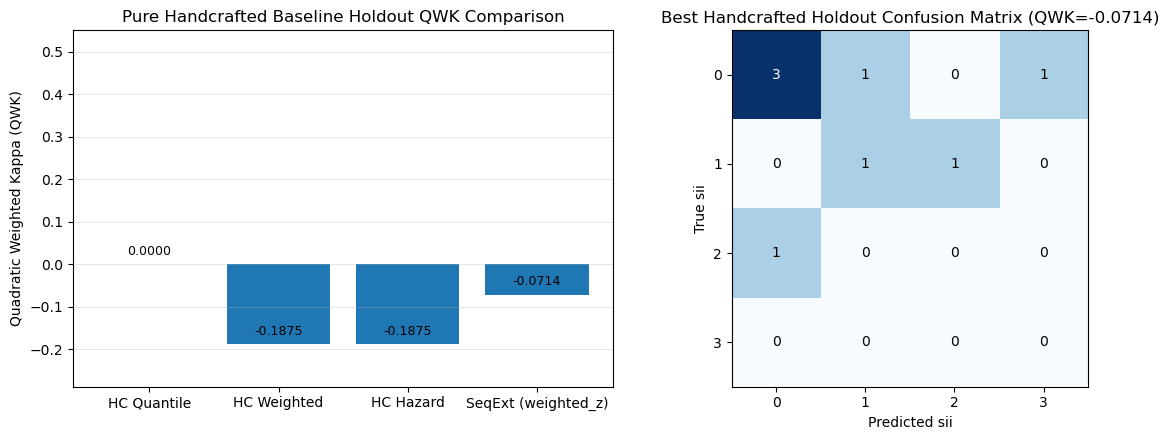

Saved diagnostic plot: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\results_cmi_piu_handcrafted_baseline_sii_bayes\20261117_015805_handcrafted_diagnostics.png


In [11]:
if experiment_succeeded:
    seq_holdout = best_est.extractor_.transform(strip_leaky_columns(X_test))
    act_mask = seq_holdout["seq_has_actigraphy"] == 1.0
    diag_cols = [
        c for c in (
            "seq_acf_log_24h",
            "seq_c22_log_enmo_PD_PeriodicityWang_th0_01",
            "seq_tsfel_log_enmo_Spectral_entropy",
            "seq_tsfresh_log_enmo_mean",
            "seq_tsflex_log_enmo_mean_w=6h_mean",
            "seq_sri",
            "seq_circ_sleep_dur_h",
            "seq_webster_tst_h",
            "seq_sadeh_night_efficiency",
            "seq_missing_bin_frac",
        ) if c in seq_holdout.columns
    ]
    diag_df = seq_holdout.loc[act_mask, diag_cols].copy()
    diag_df["sii"] = y_test.loc[diag_df.index].values
    print(f"Holdout multi-library actigraphy summary across {len(diag_df)} subjects with wearable data:")
    if len(diag_df) > 0:
        display(diag_df.groupby("sii")[diag_cols[:5]].agg(["count", "mean", "median"]))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ax0 = axes[0]
    models_lbl = ["HC Quantile", "HC Weighted", "HC Hazard", f"SeqExt ({best_est.scoring_rule[:10]})"]
    qwk_vals = [hc_quant_qwk, hc_weighted_qwk, hc_hazard_qwk, best_qwk]
    bars = ax0.bar(models_lbl, qwk_vals)
    ax0.set_ylabel("Quadratic Weighted Kappa (QWK)")
    ax0.set_title("Pure Handcrafted Baseline Holdout QWK Comparison")
    ax0.set_ylim(min(min(qwk_vals) - 0.1, -0.05), max(max(qwk_vals) + 0.15, 0.55))
    ax0.grid(axis="y", alpha=0.3)
    for bar, val in zip(bars, qwk_vals):
        ax0.text(bar.get_x() + bar.get_width() / 2.0, val + 0.015, f"{val:.4f}", ha="center", va="bottom", fontsize=9)

    ax1 = axes[1]
    cm = np.asarray(eval_results["confusion_matrix"])
    ax1.imshow(cm, cmap="Blues")
    ax1.set_xticks([0, 1, 2, 3])
    ax1.set_yticks([0, 1, 2, 3])
    ax1.set_xlabel("Predicted sii")
    ax1.set_ylabel("True sii")
    ax1.set_title(f"Best Handcrafted Holdout Confusion Matrix (QWK={best_qwk:.4f})")
    for i in range(4):
        for j in range(4):
            ax1.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() * 0.5 else "black")
    plt.tight_layout()
    plt.show()


In [12]:
test_df = load_cmi_dataset(data_root=data_root, split="test", dropna_target=False)
sample_sub_path = data_root / "sample_submission.csv"

sub_workspace_path = (Path(workspace_root) / "submission.csv") if save_results else None

submission_df = export_submission(
    search.best_estimator_,
    test_df,
    output_path=sub_workspace_path,
    sample_sub_path=sample_sub_path if sample_sub_path.exists() else None,
)

assert list(submission_df.columns) == ["id", "sii"]
assert submission_df["sii"].isna().sum() == 0
assert submission_df["sii"].isin([0, 1, 2, 3]).all()

if sub_workspace_path is not None:
    print(f"Submission written to {sub_workspace_path}")
else:
    print("Sample/debug run: skipped writing submission.csv and results files (set save_results = True to persist).")
print("Test rows:", len(submission_df), "| Predicted sii distribution:", submission_df["sii"].value_counts().sort_index().to_dict())
display(submission_df.head(10))
if validation_runs["experiments_path"]:
    print("Experiments CSV:", validation_runs["experiments_path"])
    print("Summary JSON:", validation_runs["summary_path"])


Submission written to c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\submission.csv and c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\results_cmi_piu_handcrafted_baseline_sii_bayes\20261117_015805_submission.csv
Test rows: 20 | Predicted sii distribution: {0: 6, 1: 11, 2: 3}


,id,sii
0,00008ff9,1
1,000fd460,0
2,00105258,1
3,00115b9f,0
4,0016bb22,2
5,001f3379,0
6,0038ba98,1
7,0068a485,1
8,0069fbed,2
9,0083e397,2


Experiments CSV: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\results_cmi_piu_handcrafted_baseline_sii_bayes\20261117_015805_cmi_piu_handcrafted_baseline_stratified_subject_bayes_cv.csv
Summary JSON: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\results_cmi_piu_handcrafted_baseline_sii_bayes\20261117_015805_cmi_piu_handcrafted_baseline_summary.json
